# Diagnostics outside the fitting objective

The appendix on diagnostics outside the fitting objective (Tables 15-17).

GyroSplat compresses each snapshot separately, with the snapshot and its target diagnostics at hand: the fitted flux error measures how well this encoding step succeeds. The checks here look at quantities the objective does not fit: other views of the heat flux, flux modes held out of the fit, and the solver restarted from a reconstructed snapshot.

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = pathlib.Path.cwd()
while not (REPO / "neugk").exists():  # the repository root
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
RESULTS = REPO / "neugk/gyrosplat/results"
CONFIGS = REPO / "configs/gyrosplat"

from neugk.gyrosplat.eval.paper import experiments as X
from neugk.gyrosplat.eval.paper import load_experiments, load_rows

rows = load_rows(RESULTS / "rows/gkw_rows.jsonl")
exp = load_experiments(RESULTS / "experiments")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

import statistics

from neugk.gyrosplat.eval.paper.figures import heldout_figure, restart_figure

## Other views of the heat flux (Table 15)

Median relative L1 errors over the 39 snapshots of the heat flux resolved radially, Q(kx), along the field line, Q(s), and in velocity space, Q(v∥, μ), and of the pointwise flux integrand. The Fourier and wavelet codes are their byte-matched runs; the other methods their stored fit (one seed). The spatial views stay accurate; the velocity-resolved and pointwise flux are less accurate than for the neural field + physics and the AE.

In [2]:
display(Markdown(X.views_table(exp)))

| method | Q(kx) | Q(s) | Q(v∥,μ) | pointwise |
|---|---|---|---|---|
| *CR ≈ 302×* | | | | |
| GyroSplat | 0.142 | 0.072 | 0.433 | 0.934 |
| NF + physics | 0.159 | 0.044 | 0.192 | 0.513 |
| Fourier + refinement | 0.146 | 0.120 | 0.758 | 2.874 |
| Haar + refinement | 0.979 | 1.059 | 3.003 | 16.675 |
| Splats, field only | 0.267 | 0.267 | 0.302 | 0.598 |
| NF, field only | 0.173 | 0.173 | 0.177 | 0.470 |
| AE | 0.106 | 0.069 | 0.108 | 0.498 |
| VAE | 0.157 | 0.096 | 0.134 | 0.595 |
| VQ-VAE | 0.212 | 0.198 | 0.205 | 0.588 |
| Fourier top-K | 0.289 | 0.302 | 0.568 | 2.755 |
| PCA | 0.538 | 0.455 | 0.777 | 1.036 |
| ZFP | 0.979 | 0.979 | 0.944 | 1.163 |
| SZ3 | 1.246 | 1.244 | 1.360 | 4.476 |
| Wavelet Haar | 1.009 | 1.009 | 0.994 | 1.002 |
| Wavelet bior4.4 | 1.138 | 1.137 | 1.407 | 2.334 |
| *CR ≈ 142×* | | | | |
| GyroSplat | 0.120 | 0.064 | 0.341 | 0.799 |
| NF + physics | 0.129 | 0.050 | 0.176 | 0.476 |
| Fourier + refinement | 0.090 | 0.083 | 0.475 | 2.350 |
| Haar + refinement | 0.399 | 0.480 | 1.914 | 5.178 |
| Splats, field only | 0.161 | 0.162 | 0.184 | 0.479 |
| NF, field only | 0.145 | 0.145 | 0.149 | 0.438 |
| Fourier top-K | 0.151 | 0.152 | 0.355 | 2.317 |
| PCA | 0.371 | 0.312 | 0.579 | 0.947 |
| ZFP | 0.799 | 0.798 | 0.795 | 1.100 |
| SZ3 | 0.536 | 0.518 | 0.796 | 2.508 |
| Wavelet Haar | 1.015 | 1.015 | 0.989 | 1.002 |
| Wavelet bior4.4 | 1.227 | 1.227 | 1.403 | 2.274 |

## Flux fitted on half of the modes (Table 16)

GyroSplat at 302× on nine snapshots, with the flux objective and the Gauss-Newton refinement restricted to the even (2, 4, ..., 30) or the odd (1, 3, ..., 31) binormal modes; the field and potential terms still see the whole snapshot. The held-out error is measured on the omitted modes only; the potential-PSNR change is against the fit of every mode. Accuracy on the fitted modes does not carry over to the omitted ones.

In [3]:
display(Markdown(X.heldout_table(exp)))
lines = ["| fitted | snapshot | fitted flux | held-out flux | held-out, fit on every mode | ΔPSNR_φ (dB) |", "|---|---|---|---|---|---|"]
for r in sorted(X.heldout_rows(exp), key=lambda r: (r["fitted"], r["snapshot"])):
    lines.append(f"| {r['fitted']} | {r['snapshot']} | {r['fitted_flux']:.1e} | {r['heldout_flux']:.3f} | "
                 f"{r['all_modes_heldout_flux']:.1e} | {r['delta_psnr_phi']:+.2f} |")
display(Markdown("\n".join(lines)))

| fitted modes | fitted flux relL1 | held-out flux relL1 | ΔPSNR_φ (dB) |
|---|---|---|---|
| Even | 2.5×10⁻⁸ | 0.212 | -0.06 |
| Odd | 1.4×10⁻⁷ | 0.334 | -0.09 |

| fitted | snapshot | fitted flux | held-out flux | held-out, fit on every mode | ΔPSNR_φ (dB) |
|---|---|---|---|---|---|
| even | extra_iteration_0_t150 | 5.3e-09 | 0.186 | 4.0e-07 | +0.20 |
| even | extra_iteration_15_t150 | 2.5e-08 | 0.120 | 4.7e-07 | +0.12 |
| even | iteration_100_t150 | 1.4e-08 | 0.120 | 3.3e-07 | +0.20 |
| even | iteration_13_t100 | 6.5e-08 | 0.321 | 3.2e-07 | -0.11 |
| even | iteration_204_t32 | 2.0e-08 | 0.203 | 3.7e-06 | -0.06 |
| even | iteration_50_t32 | 3.2e-08 | 0.231 | 1.3e-07 | -0.13 |
| even | iteration_5_t20 | 3.4e-08 | 0.212 | 9.3e-06 | -0.12 |
| even | iteration_877_t20 | 4.4e-09 | 0.348 | 2.0e-08 | -0.16 |
| even | iteration_893_t32 | 4.1e-08 | 0.268 | 6.8e-08 | +0.07 |
| odd | extra_iteration_0_t150 | 3.2e-07 | 0.316 | 4.5e-07 | +0.15 |
| odd | extra_iteration_15_t150 | 7.1e-07 | 0.479 | 1.2e-06 | +0.05 |
| odd | iteration_100_t150 | 2.6e-07 | 0.545 | 1.9e-06 | +0.27 |
| odd | iteration_13_t100 | 3.6e-08 | 0.345 | 3.6e-07 | -0.12 |
| odd | iteration_204_t32 | 1.4e-07 | 0.334 | 3.9e-06 | -0.05 |
| odd | iteration_50_t32 | 7.9e-09 | 0.299 | 3.5e-07 | -0.09 |
| odd | iteration_5_t20 | 8.8e-06 | 0.229 | 1.2e-05 | -0.15 |
| odd | iteration_877_t20 | 5.7e-10 | 0.342 | 3.5e-09 | -0.15 |
| odd | iteration_893_t32 | 8.6e-08 | 0.308 | 2.8e-08 | -0.12 |

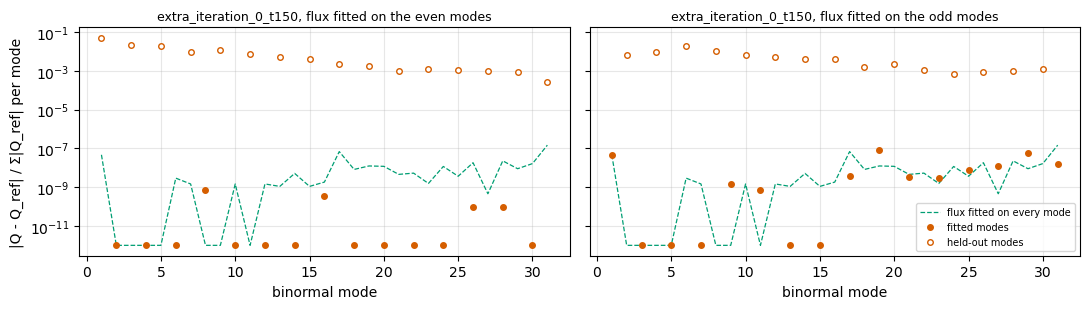

In [4]:
fig = heldout_figure(exp)
fig.savefig(FIGURES / "heldout_modes.pdf", bbox_inches="tight")
plt.show()

## Solver restarts (Table 17)

The gyrokinetic solver restarted from eight original snapshots and from their 302× reconstructions, with the trajectory's own parameters. The reference is the restart from the original snapshot; the restart from the original plus a 1e-6 perturbation shows how fast two nearby states separate on their own. Early error: median over 0 < t ≤ 5 of |Q − Q_ref| / mean |Q_ref|; departure time: the first of three consecutive samples with that error above 10%. One GyroSplat restart (at t ≈ 102) and one AE restart (at t ≈ 16) become non-finite; each is cut at its last finite sample and still counts in the early window.

In [5]:
display(Markdown(X.restart_table(exp)))
runs = X.load_restarts(exp)
lines = ["| snapshot | " + " | ".join(X.RESTART_STATES) + " |", "|---|" + "---|" * len(X.RESTART_STATES)]
for snap, states in sorted(runs.items()):
    cells = []
    for s in X.RESTART_STATES:
        m = X.restart_metrics(states[s], states["truth"])
        dep = "never" if m["departure"] is None else f"{m['departure']:.0f}"
        cells.append(f"{100 * m['early']:.1f}% / {dep}" + ("" if m["blowup"] is None else f" (non-finite at t = {m['blowup']:.0f})"))
    lines.append(f"| {snap} | " + " | ".join(cells) + " |")
display(Markdown("early error / departure time per restart\n\n" + "\n".join(lines)))

| initial state | early flux error (%) | 10% departure time | runs |
|---|---|---|---|
| Original + 1e-6 perturbation | 0.0 | 72 | 8 |
| GyroSplat | 2.4 | 22 | 8, 1 non-finite |
| NF + physics | 12.2 | 7 | 8 |
| AE | 3.6 | 15 | 8, 1 non-finite |

early error / departure time per restart

| snapshot | truth_perturbed | gyrosplat | neural_field_physics | autoencoder |
|---|---|---|---|---|
| extra_iteration_0_t150 | 0.0% / 53 | 4.5% / 48 | 4.4% / 74 | 0.9% / 59 |
| extra_iteration_15_t150 | 0.0% / 54 | 1.2% / 68 | 7.1% / 48 | 4.7% / 7 |
| iteration_13_t100 | 0.0% / 72 | 6.0% / 17 (non-finite at t = 102) | 15.4% / 1 | 1.5% / 19 |
| iteration_204_t32 | 0.0% / 100 | 2.3% / 11 | 13.7% / 1 | 3.7% / 11 |
| iteration_50_t32 | 0.0% / 76 | 0.6% / 28 | 18.9% / 1 | 9.4% / 4 |
| iteration_5_t20 | 0.0% / never | 3.9% / 7 | 16.3% / 1 | 3.5% / 6 (non-finite at t = 16) |
| iteration_877_t20 | 0.0% / 89 | 1.3% / 16 | 10.0% / 18 | 3.4% / 41 |
| iteration_893_t32 | 0.0% / 38 | 2.4% / 29 | 10.7% / 12 | 5.7% / 32 |

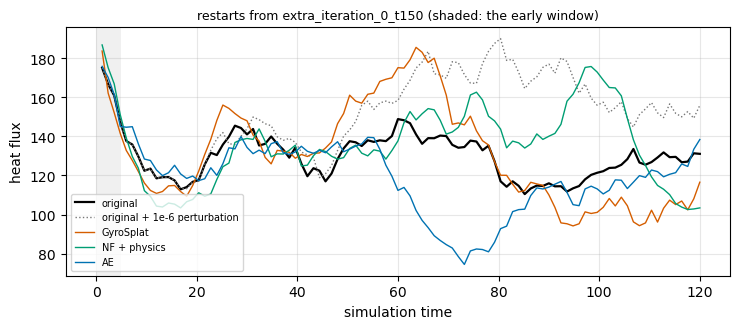

In [6]:
fig = restart_figure(exp)
fig.savefig(FIGURES / "restarts.pdf", bbox_inches="tight")
plt.show()